In [1]:

# CFCO PROJECT
# DAY 2 - INITIAL DATA EXTRACTION

import pandas as pd
import numpy as np

file_path = "CMO-Historical-Data-Monthly.xlsx"

raw = pd.read_excel(
    file_path,
    sheet_name="Monthly Prices",
    header=None
)

print("Original dataset shape:", raw.shape)

# Identify the actual headers and units
commodity_headers = raw.iloc[4].tolist()
commodity_units = raw.iloc[5].tolist()

print("\nCommodity column information:")

for i, name in enumerate(commodity_headers):
    if name in [
        "Soybeans",
        "Maize",
        "Rice, Thai 5% ",
        "Wheat, US HRW"
    ]:
        print(name, "-", commodity_units[i])


Original dataset shape: (808, 72)

Commodity column information:
Soybeans - ($/mt)
Maize - ($/mt)
Rice, Thai 5%  - ($/mt)
Wheat, US HRW - ($/mt)


In [2]:

# Extract only our four selected commodity series

selected_columns = {
    "Soybeans": 24,
    "Maize": 30,
    "Rice_Thai_5pct": 32,
    "Wheat_US_HRW": 37
}

# Monthly data starts at row 6
data = raw.iloc[6:, [0] + list(selected_columns.values())].copy()

data.columns = ["Period"] + list(selected_columns.keys())

print("Extracted dataset:")
display(data.head())

print("\nLast five records:")
display(data.tail())


Extracted dataset:


,Period,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW
6,1960M01,94,45,104.5,59.9
7,1960M02,91,44,103.5,61
8,1960M03,92,45,103.8,61.7
9,1960M04,93,45,101,61
10,1960M05,93,48,102.2,57.7



Last five records:


,Period,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW
803,2026M06,464,197.1,494,286
804,2026M07,478,213.4,467,310
805,2026M08,482,224,471,330
806,2026M09,524,239.6,482,347
807,2026M10,515,226.5,489,317


In [3]:

# Convert the original period format into dates
# Example: 2026M10 becomes 2026-10-01

data["Date"] = pd.to_datetime(
    data["Period"].astype(str).str.replace("M", "-", regex=False)
    + "-01",
    format="%Y-%m-%d",
    errors="coerce"
)

# Select the project analysis period
analysis_data = data[
    (data["Date"] >= "2021-01-01") &
    (data["Date"] <= "2026-10-01")
].copy()

print("Analysis period:")
print(analysis_data["Date"].min())
print(analysis_data["Date"].max())

print("Number of monthly records:", len(analysis_data))


Analysis period:
2021-01-01 00:00:00
2026-10-01 00:00:00
Number of monthly records: 70


In [4]:

# DATA TYPE CONVERSION

# Work on a separate copy
clean_data = analysis_data.copy()

# Convert commodity prices into numeric values
commodity_columns = [
    "Soybeans",
    "Maize",
    "Rice_Thai_5pct",
    "Wheat_US_HRW"
]

for col in commodity_columns:
    clean_data[col] = pd.to_numeric(
        clean_data[col],
        errors="coerce"
    )

print("DATA TYPES AFTER CONVERSION")
print(clean_data.dtypes)

display(clean_data.head())


DATA TYPES AFTER CONVERSION
Period                    object
Soybeans                   int64
Maize                    float64
Rice_Thai_5pct             int64
Wheat_US_HRW             float64
Date              datetime64[ns]
dtype: object


,Period,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW,Date
738,2021M01,576,234.5,545,289.3,2021-01-01
739,2021M02,578,245.2,557,289.4,2021-02-01
740,2021M03,586,245.2,525,273.1,2021-03-01
741,2021M04,597,268.2,495,281.0,2021-04-01
742,2021M05,647,305.3,493,297.3,2021-05-01


In [5]:

# MISSING VALUE ANALYSIS

missing_report = pd.DataFrame({
    "Column": clean_data.columns,
    "Missing_Count": clean_data.isnull().sum().values,
    "Missing_Percentage": (
        clean_data.isnull().mean().values * 100
    )
})

display(missing_report)

print("\nTotal missing values:")
print(clean_data.isnull().sum().sum())


,Column,Missing_Count,Missing_Percentage
0,Period,0,0.0
1,Soybeans,0,0.0
2,Maize,0,0.0
3,Rice_Thai_5pct,0,0.0
4,Wheat_US_HRW,0,0.0
5,Date,0,0.0



Total missing values:
0


In [6]:

# DUPLICATE DATE CHECK

duplicate_count = clean_data["Date"].duplicated().sum()

print("Duplicate dates:", duplicate_count)

duplicate_records = clean_data[
    clean_data["Date"].duplicated(keep=False)
]

display(duplicate_records)


Duplicate dates: 0


,Period,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW,Date


In [7]:

# PRICE VALIDATION

for col in commodity_columns:

    print("\nCommodity:", col)

    print("Minimum:", clean_data[col].min())
    print("Maximum:", clean_data[col].max())
    print("Average:", clean_data[col].mean())

    invalid_prices = clean_data[
        clean_data[col] <= 0
    ]

    print("Non-positive prices:", len(invalid_prices))



Commodity: Soybeans
Minimum: 391
Maximum: 737
Average: 536.5428571428571
Non-positive prices: 0

Commodity: Maize
Minimum: 170.3
Maximum: 348.2
Average: 240.78714285714284
Non-positive prices: 0

Commodity: Rice_Thai_5pct
Minimum: 356
Maximum: 660
Average: 482.6142857142857
Non-positive prices: 0

Commodity: Wheat_US_HRW
Minimum: 230.8
Maximum: 522.3
Average: 316.1585714285714
Non-positive prices: 0


In [8]:

# FINAL DATA QUALITY SUMMARY

quality_summary = pd.DataFrame({
    "Test": [
        "Total Records",
        "Duplicate Dates",
        "Missing Values",
        "Invalid Dates",
        "Negative or Zero Prices"
    ],

    "Result": [
        len(clean_data),
        clean_data["Date"].duplicated().sum(),
        clean_data.isnull().sum().sum(),
        clean_data["Date"].isnull().sum(),
        sum(
            (clean_data[c] <= 0).sum()
            for c in commodity_columns
        )
    ]
})

display(quality_summary)


,Test,Result
0,Total Records,70
1,Duplicate Dates,0
2,Missing Values,0
3,Invalid Dates,0
4,Negative or Zero Prices,0


In [9]:

# EXPORT VALIDATED DATASET

# Preserve only validated records
final_data = clean_data.dropna(
    subset=["Date"] + commodity_columns
).copy()

# Sort chronologically
final_data = final_data.sort_values("Date")

# Keep one observation per month only if unique
assert not final_data["Date"].duplicated().any()

# Check the expected analysis period
assert len(final_data) == 70
assert final_data["Date"].min() == pd.Timestamp("2021-01-01")
assert final_data["Date"].max() == pd.Timestamp("2026-10-01")

# Export CSV
final_data.to_csv(
    "CFCO_Cleaned_Commodity_Prices.csv",
    index=False
)

# Export Excel
with pd.ExcelWriter(
    "CFCO_Cleaned_Commodity_Prices.xlsx"
) as writer:

    final_data.to_excel(
        writer,
        sheet_name="Cleaned_Data",
        index=False
    )

    quality_summary.to_excel(
        writer,
        sheet_name="Quality_Report",
        index=False
    )

print("Validated dataset exported successfully!")
print("Final records:", len(final_data))


Validated dataset exported successfully!
Final records: 70


In [10]:

# PREPARE DATA FOR STATISTICAL ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use our validated dataset
df = final_data.copy()

# Ensure chronological order
df = df.sort_values("Date").reset_index(drop=True)

commodities = [
    "Soybeans",
    "Maize",
    "Rice_Thai_5pct",
    "Wheat_US_HRW"
]

print("Dataset ready for analysis")
print("Total observations:", len(df))
print("First month:", df["Date"].min())
print("Last month:", df["Date"].max())

display(df.head())


Dataset ready for analysis
Total observations: 70
First month: 2021-01-01 00:00:00
Last month: 2026-10-01 00:00:00


,Period,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW,Date
0,2021M01,576,234.5,545,289.3,2021-01-01
1,2021M02,578,245.2,557,289.4,2021-02-01
2,2021M03,586,245.2,525,273.1,2021-03-01
3,2021M04,597,268.2,495,281.0,2021-04-01
4,2021M05,647,305.3,493,297.3,2021-05-01


In [11]:

# MONTH-ON-MONTH PRICE CHANGES

mom_changes = df[commodities].pct_change(
    fill_method=None
) * 100

mom_changes.columns = [
    col + "_MoM_Change_Pct"
    for col in commodities
]

# Combine with original dataset
analysis_df = pd.concat(
    [df, mom_changes],
    axis=1
)

display(analysis_df.head(15))


,Period,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW,Date,Soybeans_MoM_Change_Pct,Maize_MoM_Change_Pct,Rice_Thai_5pct_MoM_Change_Pct,Wheat_US_HRW_MoM_Change_Pct
0,2021M01,576,234.5,545,289.3,2021-01-01,NaN,NaN,NaN,NaN
1,2021M02,578,245.2,557,289.4,2021-02-01,0.347222,4.562900,2.201835,0.034566
2,2021M03,586,245.2,525,273.1,2021-03-01,1.384083,0.000000,-5.745063,-5.632343
3,2021M04,597,268.2,495,281.0,2021-04-01,1.877133,9.380098,-5.714286,2.892713
4,2021M05,647,305.3,493,297.3,2021-05-01,8.375209,13.832960,-0.404040,5.800712
5,2021M06,615,292.6,466,285.6,2021-06-01,-4.945904,-4.159843,-5.476673,-3.935419
6,2021M07,600,278.4,414,294.3,2021-07-01,-2.439024,-4.853042,-11.158798,3.046218
7,2021M08,586,256.6,403,324.5,2021-08-01,-2.333333,-7.830460,-2.657005,10.261638
8,2021M09,558,235.6,400,337.6,2021-09-01,-4.778157,-8.183944,-0.744417,4.036980
9,2021M10,552,239.6,401,354.7,2021-10-01,-1.075269,1.697793,0.250000,5.065166


In [12]:

# YEAR-ON-YEAR PRICE CHANGES

yoy_changes = df[commodities].pct_change(
    periods=12,
    fill_method=None
) * 100

yoy_changes.columns = [
    col + "_YoY_Change_Pct"
    for col in commodities
]

analysis_df = pd.concat(
    [analysis_df, yoy_changes],
    axis=1
)

display(
    analysis_df[
        ["Date"] + list(yoy_changes.columns)
    ].tail(15)
)


,Date,Soybeans_YoY_Change_Pct,Maize_YoY_Change_Pct,Rice_Thai_5pct_YoY_Change_Pct,Wheat_US_HRW_YoY_Change_Pct
55,2025-08-01,1.750000,8.925426,-36.332767,-7.891590
56,2025-09-01,3.324808,6.702703,-35.517241,-13.311086
57,2025-10-01,-8.597285,4.098791,-30.873786,-15.426896
58,2025-11-01,2.293578,0.347740,-27.984344,-3.112687
59,2025-12-01,7.579462,1.530109,-19.544592,-3.727201
60,2026-01-01,3.406326,-4.617537,-14.644351,-1.652893
61,2026-02-01,11.407767,-5.115437,-6.407323,-2.645503
62,2026-03-01,17.955112,2.555448,-10.352941,8.065779
63,2026-04-01,13.480392,-0.465116,-2.891566,12.980769
64,2026-05-01,14.251208,6.032369,2.088167,27.848101


In [13]:

# NORMALISED COMMODITY PRICE INDEX

price_index = (
    df[commodities]
    .div(df[commodities].iloc[0])
    * 100
)

price_index.insert(
    0,
    "Date",
    df["Date"]
)

print("COMMODITY PRICE INDEX")
print("Base month: January 2021 = 100")

display(price_index.head(10))
display(price_index.tail(10))


COMMODITY PRICE INDEX
Base month: January 2021 = 100


,Date,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW
0,2021-01-01,100.000000,100.000000,100.000000,100.000000
1,2021-02-01,100.347222,104.562900,102.201835,100.034566
2,2021-03-01,101.736111,104.562900,96.330275,94.400277
3,2021-04-01,103.645833,114.371002,90.825688,97.131006
4,2021-05-01,112.326389,130.191898,90.458716,102.765296
5,2021-06-01,106.770833,124.776119,85.504587,98.721051
6,2021-07-01,104.166667,118.720682,75.963303,101.728310
7,2021-08-01,101.736111,109.424307,73.944954,112.167300
8,2021-09-01,96.875000,100.469083,73.394495,116.695472
9,2021-10-01,95.833333,102.174840,73.577982,122.606291


,Date,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW
60,2026-01-01,73.784722,87.206823,74.862385,86.380919
61,2026-02-01,79.687500,89.381663,75.045872,89.042516
62,2026-03-01,82.118056,90.703625,69.908257,95.402696
63,2026-04-01,80.381944,91.257996,73.944954,97.476668
64,2026-05-01,82.118056,92.196162,80.733945,104.735569
65,2026-06-01,80.555556,84.051173,90.642202,98.859316
66,2026-07-01,82.986111,91.002132,85.688073,107.155202
67,2026-08-01,83.680556,95.522388,86.422018,114.068441
68,2026-09-01,90.972222,102.174840,88.440367,119.944694
69,2026-10-01,89.409722,96.588486,89.724771,109.574836


In [ ]:

# VOLATILITY ANALYSIS

volatility = mom_changes.std()

volatility_report = pd.DataFrame({
    "Commodity": commodities,
    "Average_Monthly_Change_Pct": [
        mom_changes[col].mean()
        for col in commodities
    ],
    "Monthly_Volatility_Pct": [
        volatility[col]
        for col in commodities
    ],
    "Annualised_Volatility_Pct": [
        volatility[col] * np.sqrt(12)
        for col in commodities
    ]
})

volatility_report = volatility_report.sort_values(
    "Monthly_Volatility_Pct",
    ascending=False
)

display(volatility_report.round(2))


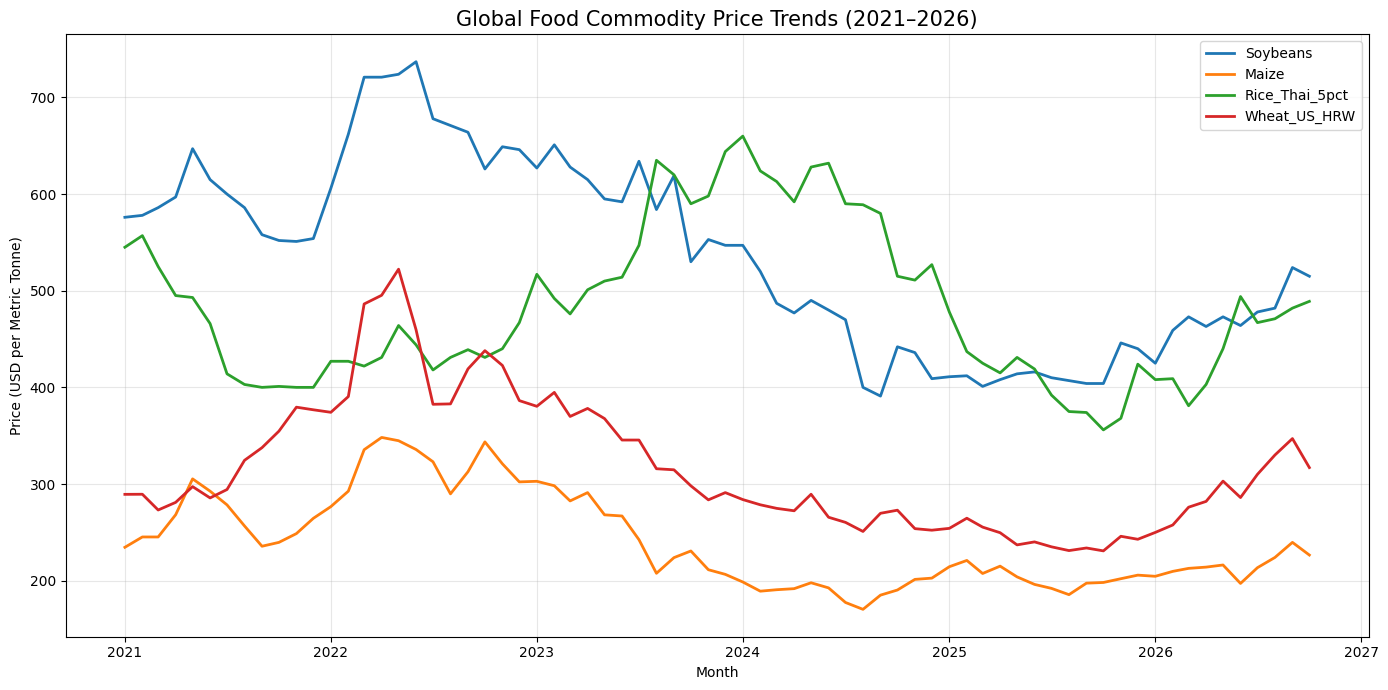

In [14]:

# COMMODITY PRICE TREND CHART

plt.figure(figsize=(14, 7))

for commodity in commodities:
    plt.plot(
        df["Date"],
        df[commodity],
        label=commodity,
        linewidth=2
    )

plt.title(
    "Global Food Commodity Price Trends (2021–2026)",
    fontsize=15
)

plt.xlabel("Month")
plt.ylabel("Price (USD per Metric Tonne)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "CFCO_Commodity_Price_Trends.png",
    dpi=300
)

plt.show()


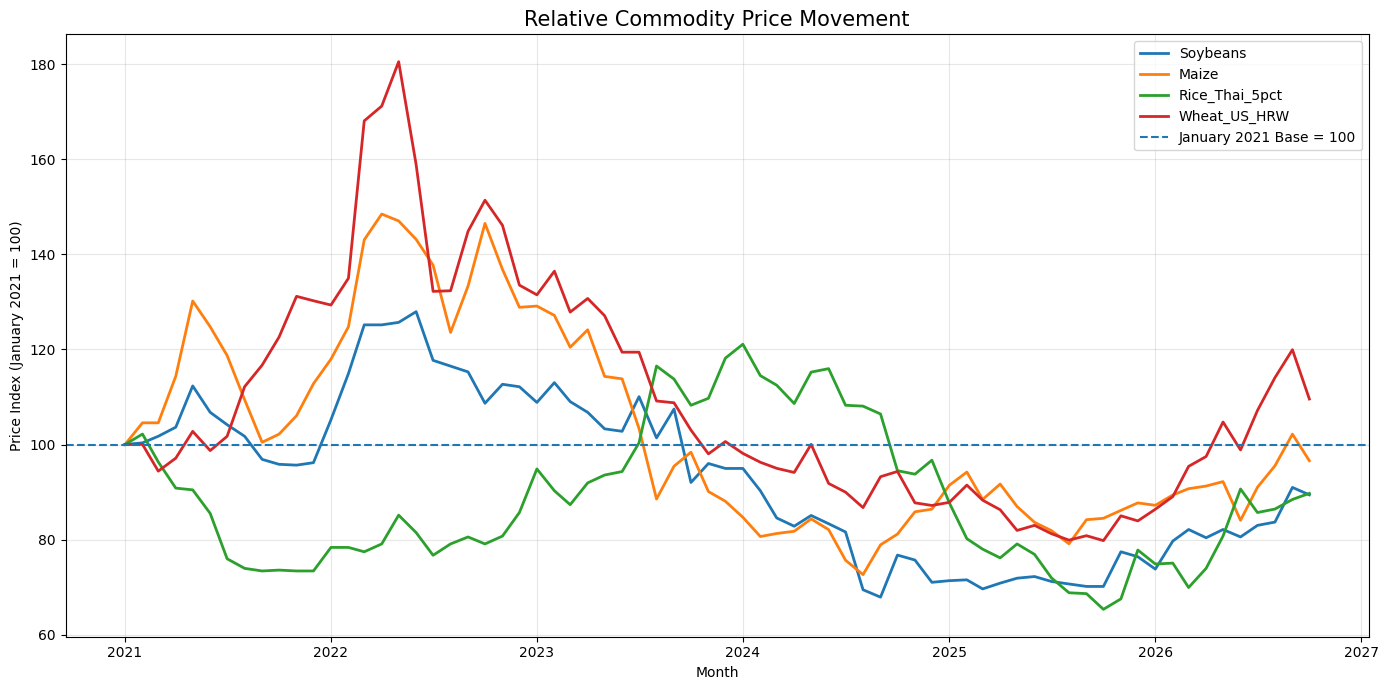

In [15]:

# NORMALISED PRICE INDEX CHART

plt.figure(figsize=(14, 7))

for commodity in commodities:
    plt.plot(
        price_index["Date"],
        price_index[commodity],
        label=commodity,
        linewidth=2
    )

plt.axhline(
    y=100,
    linestyle="--",
    label="January 2021 Base = 100"
)

plt.title(
    "Relative Commodity Price Movement",
    fontsize=15
)

plt.xlabel("Month")
plt.ylabel("Price Index (January 2021 = 100)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "CFCO_Normalised_Price_Index.png",
    dpi=300
)

plt.show()


COMMODITY PRICE CORRELATION MATRIX


,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW
Soybeans,1.000,0.889,0.032,0.861
Maize,0.889,1.000,-0.286,0.880
Rice_Thai_5pct,0.032,-0.286,1.000,-0.141
Wheat_US_HRW,0.861,0.880,-0.141,1.000


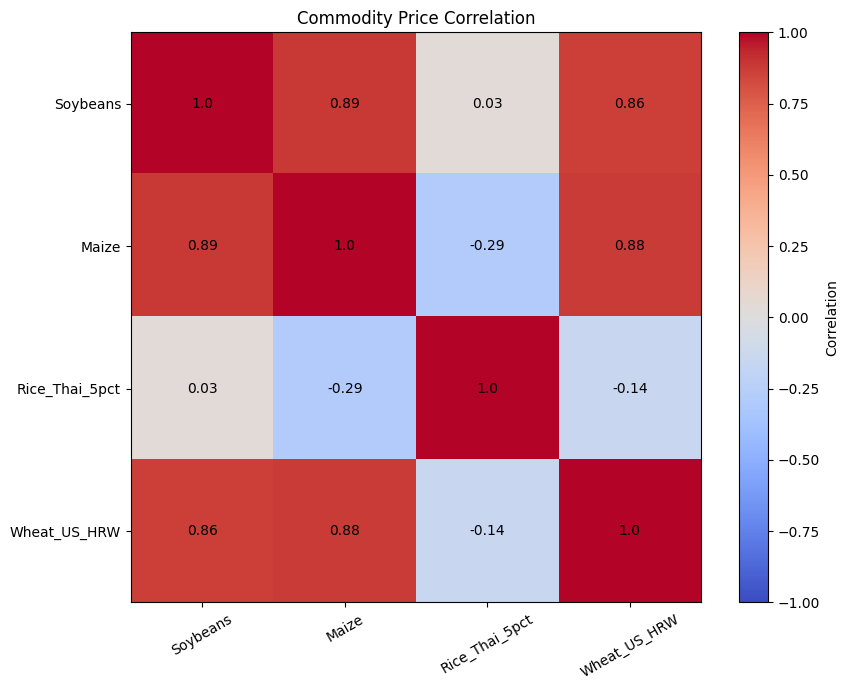

In [16]:

# COMMODITY PRICE CORRELATION

correlation_matrix = df[commodities].corr()

print("COMMODITY PRICE CORRELATION MATRIX")

display(correlation_matrix.round(3))

plt.figure(figsize=(9, 7))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(commodities)),
    commodities,
    rotation=30
)

plt.yticks(
    range(len(commodities)),
    commodities
)

plt.title("Commodity Price Correlation")

for i in range(len(commodities)):
    for j in range(len(commodities)):
        plt.text(
            j, i,
            round(correlation_matrix.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.savefig("CFCO_Correlation_Matrix.png", dpi=300)
plt.show()


In [17]:

# ANNUAL AVERAGE COMMODITY PRICES

df["Year"] = df["Date"].dt.year

annual_prices = (
    df.groupby("Year")[commodities]
    .mean()
    .round(2)
)

display(annual_prices)


,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW
Year,,,,
2021,583.33,259.53,458.25,315.26
2022,675.42,318.80,436.75,429.98
2023,597.92,252.66,553.67,340.44
2024,462.42,190.60,588.42,268.69
2025,414.42,203.20,407.83,243.35
2026,475.60,215.76,444.40,295.85


In [20]:

# ============================================
# CFCO - FIX VOLATILITY REPORT
# ============================================

# Ensure monthly percentage changes exist
mom_changes = df[commodities].pct_change(
    fill_method=None
) * 100

# Calculate volatility report
volatility_report = pd.DataFrame({
    "Commodity": commodities,

    "Average_Monthly_Change_Pct": [
        mom_changes[col].mean()
        for col in commodities
    ],

    "Monthly_Volatility_Pct": [
        mom_changes[col].std()
        for col in commodities
    ],

    "Annualised_Volatility_Pct": [
        mom_changes[col].std() * np.sqrt(12)
        for col in commodities
    ]
})

volatility_report = volatility_report.sort_values(
    "Monthly_Volatility_Pct",
    ascending=False
)

display(volatility_report.round(2))

print("Volatility report created successfully!")


,Commodity,Average_Monthly_Change_Pct,Monthly_Volatility_Pct,Annualised_Volatility_Pct
3,Wheat_US_HRW,0.31,6.11,21.16
1,Maize,0.13,5.97,20.68
2,Rice_Thai_5pct,-0.00,5.67,19.64
0,Soybeans,-0.03,5.09,17.65


Volatility report created successfully!


In [21]:

with pd.ExcelWriter(
    "CFCO_Day3_Statistical_Analysis.xlsx"
) as writer:

    analysis_df.to_excel(
        writer,
        sheet_name="Monthly_Changes",
        index=False
    )

    price_index.to_excel(
        writer,
        sheet_name="Price_Index",
        index=False
    )

    volatility_report.to_excel(
        writer,
        sheet_name="Volatility",
        index=False
    )

    annual_prices.to_excel(
        writer,
        sheet_name="Annual_Averages"
    )

    correlation_matrix.to_excel(
        writer,
        sheet_name="Correlation"
    )

print("Day 3 analytical workbook created successfully!")


Day 3 analytical workbook created successfully!


In [22]:

from google.colab import files

files.download("CFCO_Day3_Statistical_Analysis.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:

# Correlation based on monthly price returns

monthly_returns = df[commodities].pct_change(
    fill_method=None
).dropna()

return_correlation = monthly_returns.corr()

display(return_correlation.round(3))


,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW
Soybeans,1.000,0.359,-0.006,0.399
Maize,0.359,1.000,-0.186,0.543
Rice_Thai_5pct,-0.006,-0.186,1.000,-0.043
Wheat_US_HRW,0.399,0.543,-0.043,1.000


In [24]:

# Compare January 2021 with October 2026

latest_index = price_index.iloc[-1]

index_comparison = pd.DataFrame({
    "Commodity": commodities,
    "January_2021_Index": [100] * 4,
    "October_2026_Index": [
        latest_index[c] for c in commodities
    ],
    "Total_Change_Pct": [
        latest_index[c] - 100 for c in commodities
    ]
})

display(
    index_comparison.sort_values(
        "Total_Change_Pct",
        ascending=False
    ).round(2)
)


,Commodity,January_2021_Index,October_2026_Index,Total_Change_Pct
3,Wheat_US_HRW,100,109.57,9.57
1,Maize,100,96.59,-3.41
2,Rice_Thai_5pct,100,89.72,-10.28
0,Soybeans,100,89.41,-10.59


In [26]:

import pandas as pd
import numpy as np

# Commodity columns
commodities = [
    "Soybeans",
    "Maize",
    "Rice_Thai_5pct",
    "Wheat_US_HRW"
]

# Recreate monthly percentage changes
monthly_changes = clean_data[
    ["Date"] + commodities
].copy()

for col in commodities:
    monthly_changes[col + "_MoM_Pct"] = (
        clean_data[col].pct_change(fill_method=None) * 100
    )

    monthly_changes[col + "_YoY_Pct"] = (
        clean_data[col].pct_change(periods=12, fill_method=None) * 100
    )

# Recreate monthly returns correlation
monthly_returns = clean_data[commodities].pct_change(
    fill_method=None
).dropna()

return_correlation = monthly_returns.corr()

# Recreate latest price index comparison
price_index = clean_data[["Date"] + commodities].copy()

for col in commodities:
    price_index[col] = (
        clean_data[col] / clean_data[col].iloc[0]
    ) * 100

latest_index = price_index.iloc[-1]

index_comparison = pd.DataFrame({
    "Commodity": commodities,
    "January_2021_Index": [100] * len(commodities),
    "October_2026_Index": [
        latest_index[col] for col in commodities
    ],
    "Total_Change_Pct": [
        latest_index[col] - 100 for col in commodities
    ]
})

display(return_correlation.round(3))
display(index_comparison.round(2))


,Soybeans,Maize,Rice_Thai_5pct,Wheat_US_HRW
Soybeans,1.000,0.359,-0.006,0.399
Maize,0.359,1.000,-0.186,0.543
Rice_Thai_5pct,-0.006,-0.186,1.000,-0.043
Wheat_US_HRW,0.399,0.543,-0.043,1.000


,Commodity,January_2021_Index,October_2026_Index,Total_Change_Pct
0,Soybeans,100,89.41,-10.59
1,Maize,100,96.59,-3.41
2,Rice_Thai_5pct,100,89.72,-10.28
3,Wheat_US_HRW,100,109.57,9.57


In [27]:

output_file = "CFCO_Day3_Statistical_Analysis.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

    monthly_changes.to_excel(
        writer, sheet_name="Monthly_Changes", index=False
    )

    price_index.to_excel(
        writer, sheet_name="Price_Index", index=False
    )

    return_correlation.to_excel(
        writer, sheet_name="Monthly_Return_Correlation"
    )

    index_comparison.to_excel(
        writer, sheet_name="Latest_Index_Comparison", index=False
    )

print("Export completed successfully!")


Export completed successfully!


In [28]:

import pandas as pd

file_path = "CFCO_Day3_Statistical_Analysis.xlsx"

excel_file = pd.ExcelFile(file_path)

print("Worksheets in the workbook:")
for sheet in excel_file.sheet_names:
    print("-", sheet)

print("\nTotal worksheets:", len(excel_file.sheet_names))


Worksheets in the workbook:
- Monthly_Changes
- Price_Index
- Monthly_Return_Correlation
- Latest_Index_Comparison

Total worksheets: 4


In [29]:
from google.colab import files
files.download("CFCO_Day3_Statistical_Analysis.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:

import pandas as pd

# Select the four commodity columns
commodities = [
    "Soybeans",
    "Maize",
    "Rice_Thai_5pct",
    "Wheat_US_HRW"
]

# Convert wide format into long format
long_data = clean_data.melt(
    id_vars=["Date"],
    value_vars=commodities,
    var_name="commodity_code",
    value_name="price_usd_mt"
)

# Map Python column names to MySQL commodity codes
commodity_mapping = {
    "Soybeans": "SOYBEANS",
    "Maize": "MAIZE",
    "Rice_Thai_5pct": "RICE_THAI_5",
    "Wheat_US_HRW": "WHEAT_US_HRW"
}

long_data["commodity_code"] = (
    long_data["commodity_code"].map(commodity_mapping)
)

# Format dates
long_data["Date"] = pd.to_datetime(
    long_data["Date"]
).dt.strftime("%Y-%m-%d")

# Validate data
long_data["price_usd_mt"] = pd.to_numeric(
    long_data["price_usd_mt"], errors="coerce"
)

assert len(long_data) == 280, "Record count is incorrect!"
assert long_data.isnull().sum().sum() == 0, "Missing values found!"
assert long_data["price_usd_mt"].gt(0).all(), "Invalid prices found!"

# Export CSV
long_data.to_csv(
    "CFCO_Commodity_Prices_Long_Format.csv",
    index=False
)

print("Data transformation successful!")
print("Total records:", len(long_data))
print("Date range:", long_data["Date"].min(), "to", long_data["Date"].max())

display(long_data.head(10))


Data transformation successful!
Total records: 280
Date range: 2021-01-01 to 2026-10-01


,Date,commodity_code,price_usd_mt
0,2021-01-01,SOYBEANS,576.0
1,2021-02-01,SOYBEANS,578.0
2,2021-03-01,SOYBEANS,586.0
3,2021-04-01,SOYBEANS,597.0
4,2021-05-01,SOYBEANS,647.0
5,2021-06-01,SOYBEANS,615.0
6,2021-07-01,SOYBEANS,600.0
7,2021-08-01,SOYBEANS,586.0
8,2021-09-01,SOYBEANS,558.0
9,2021-10-01,SOYBEANS,552.0


In [31]:

from google.colab import files

files.download("CFCO_Commodity_Prices_Long_Format.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>